In [1]:
# Importação das bibliotecas essenciais para Visão Computacional e manipulação de arrays
import cv2
import matplotlib.pyplot as plt
import os
import numpy as np

print("Bibliotecas importadas com sucesso!")

Bibliotecas importadas com sucesso!


In [2]:
# Carrega o classificador Haar Cascade embutido no OpenCV para detecção facial
face_classifier = cv2.CascadeClassifier(
    cv2.data.haarcascades + "haarcascade_frontalface_default.xml"
)

# Caminho para a pasta onde estão as subpastas com as 5 fotos de cada pessoa
# Certifique-se de que a pasta 'imagens_faces' está no mesmo diretório do seu notebook
pasta_dataset = "imagens_faces"

print("Classificador configurado. Pronto para iniciar o processamento das imagens.")

Classificador configurado. Pronto para iniciar o processamento das imagens.



Processando pessoa pessoa_1
 -> Menor distância calculada: 5947.46
 -> Reconhecimento bem-sucedido? SIM


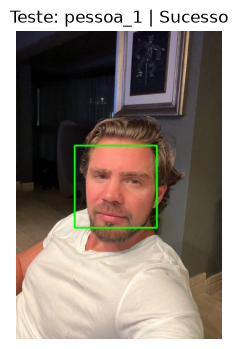


Processando pessoa pessoa_2
 -> Menor distância calculada: 4752.44
 -> Reconhecimento bem-sucedido? SIM


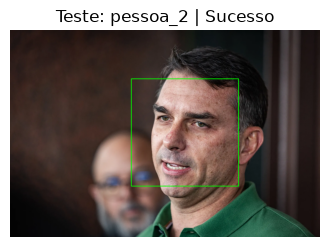


Processando pessoa pessoa_3
 -> Menor distância calculada: 4620.92
 -> Reconhecimento bem-sucedido? SIM


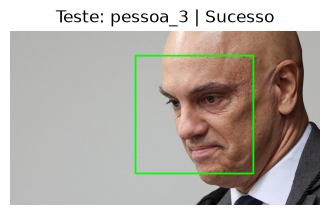


Processando pessoa pessoa_4
 -> Menor distância calculada: 6106.77
 -> Reconhecimento bem-sucedido? SIM


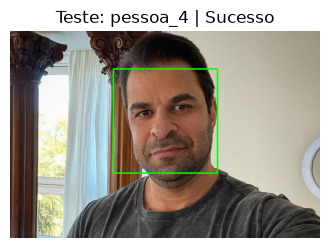


Processando pessoa pessoa_5
 -> Menor distância calculada: 4205.63
 -> Reconhecimento bem-sucedido? SIM


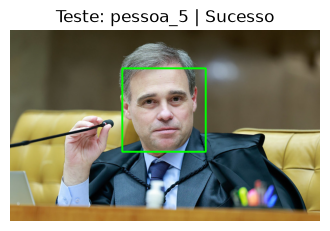

In [17]:
#Iteração das pastas de pessoas
for pessoa in os.listdir(pasta_dataset):
    caminho_pessoa = os.path.join(pasta_dataset, pessoa)

    if os.path.isdir(caminho_pessoa):
        #Filtra apenas arquivos de imagem válidos
        arquivos_pasta = os.listdir(caminho_pessoa)
        fotos = []

        for arquivo in arquivos_pasta:
            #verifica a extensão da imagem
            if arquivo.lower().endswith(('.png', '.jpg', '.jpeg')):
                fotos.append(arquivo)

        fotos.sort()

        if len(fotos) >= 5:
            print(f"\nProcessando pessoa {pessoa}")

            features_treino = []
            #1. Carrega as 4 primeiras fotos como base de referência (treino)

            for i in range(4):
                caminho_foto = os.path.join(caminho_pessoa, fotos[i])
                img = cv2.imread(caminho_foto)

                if img is None:
                    continue

                gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
                faces = face_classifier.detectMultiScale(gray, scaleFactor=1.1, minNeighbors=5, minSize=(30, 30))

                # Se encontrou a face, padroniza e guarda na lista de treino
                if len(faces) > 0:
                    (x,y,w,h) = faces[0]
                    face_roi = gray[y:y+h, x:x+w]
                    face_roi = cv2.resize(face_roi, (100,100))
                    features_treino.append(face_roi)

            ## 2. Testa a 5ª foto (foto de validação)
            caminho_teste = os.path.join(caminho_pessoa, fotos[4])
            img_teste = cv2.imread(caminho_teste)

            if img_teste is not None:
                    gray_teste = cv2.cvtColor(img_teste, cv2.COLOR_BGR2GRAY)
                    faces_teste = face_classifier.detectMultiScale(gray_teste, scaleFactor=1.05, minNeighbors=3, minSize=(30, 20))

                    if len(faces_teste) > 0:
                        (tx, ty, tw, th) = faces_teste[0]
                        face_teste_roi = gray_teste[ty:ty+th, tx:tx+tw]
                        face_teste_roi = cv2.resize(face_teste_roi, (100, 100))
                    
                    # Desenha o retângulo verde na face detectada da 5ª foto
                        cv2.rectangle(img_teste, (tx, ty), (tx + tw, ty + th), (0, 255, 0), 4)
                    
                    # 3. Compara usando Distância Euclidiana entre as matrizes de pixels
                        menor_distancia = float('inf')
                        for ref in features_treino:
                            dist = np.linalg.norm(face_teste_roi.astype("float") - ref.astype("float"))
                            if dist < menor_distancia:
                                menor_distancia = dist
                    
                        # Validação
                        sucesso = menor_distancia < 7000
                    
                        print(f" -> Menor distância calculada: {menor_distancia:.2f}")
                        print(f" -> Reconhecimento bem-sucedido? {'SIM' if sucesso else 'NÃO'}")
                    
                        # Exibe o resultado visualmente direto no Jupyter do VS Code
                        img_rgb = cv2.cvtColor(img_teste, cv2.COLOR_BGR2RGB)
                        plt.figure(figsize=(4, 4))
                        plt.imshow(img_rgb)
                        plt.title(f"Teste: {pessoa} | {'Sucesso' if sucesso else 'Falha'}")
                        plt.axis('off')
                        plt.show()
                    else:
                        print(f" -> Aviso: Nenhuma face detectada na 5ª foto de {pessoa}.")

